<img src="https://raw.githubusercontent.com/riazcseiu/fmlds2026-multimodal-workshop/main/assets/banner.png" width="100%">

# Notebook 1 · Interviews → Keywords → Weights
**The language modality**  ·  ⏱ about 20 minutes

### What you will learn
- Load three interview modalities: **on-site**, **video-based** and **virtual walkthrough**
- Discover keywords from data (frequency, TF-IDF) and with AI assistance
- Map words to a curated **keyword dictionary** (Physical Elements · Products · Activities · Atmosphere)
- Implement the **baseline sentiment-coupled weighting** algorithm from Mian & Nguyen-Tran (World 2026, §4.1)
- See the *verbosity problem* that Notebook 2 will fix

> **The story so far.** At the *Imagine Coffee Event* — a two-hour Sunday-morning pop-up market in Matsue, Japan — we asked visitors what they noticed (**interviews → language**) and we filmed what they actually did (**video → vision**).
> This workshop combines both modalities to answer one question: *do people do what they say?*

<small>Data: a reduced, anonymised teaching subset derived from Mian & Nguyen-Tran (World 2026) and Nguyen-Tran, Majiid & Mian (World 2025). Names removed, participants sub-sampled, ~10% of utterances dropped. Do not use for research claims.</small>


> **Colab tip.** This notebook opens in *view mode*. To run it, click **File → Save a copy in Drive**, then run cells with **Shift + Enter**.

In [1]:
# ▶ Run this cell first — it fetches the workshop data (about 20 s in Colab)
import os, sys, warnings
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/riazcseiu/fmlds2026-multimodal-workshop'
if IN_COLAB:
    if not os.path.exists('fmlds2026-multimodal-workshop'):
        os.system(f'git clone -q --depth 1 {REPO_URL}')
    BASE = 'fmlds2026-multimodal-workshop'
else:
    BASE = '..'          # running locally from the notebooks/ folder
DATA = os.path.join(BASE, 'data')
RESULTS = os.path.join(BASE, 'data', 'results'); os.makedirs(RESULTS, exist_ok=True)

import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 11})
COL = {'onsite': '#2A9D8F', 'video': '#4361EE', 'virtual': '#9B5DE5', 'P': '#4361EE', 'B': '#D9731A'}
print('Data folder:', os.path.abspath(DATA))

## 1 · Meet the data
Three interview modalities were collected at the **same event**:

| Modality | When | Who | Format |
|---|---|---|---|
| **On-site** (Phase 1) | During the event, Aug 2024 | 8 visitors (teaching subset, S01–S08) | ~5 min, structured |
| **Video** (Phase 2) | After the event | 4 participants (R01–R04) watched uncut event video | ~16 min, free-form |
| **Virtual** (Phase 3) | Later | Same 4 participants watched a 3-D walkthrough with design changes | ~12 min |

Every row is one utterance. `role` tells us whether the **interviewer** (`INT`) or a **participant** spoke — that matters, because the interviewer's words must not count as the participant's opinion.

In [2]:
df = pd.read_csv(f'{DATA}/interviews/imagine_coffee_all.csv')
df['n_words'] = df.text.astype(str).str.split().str.len()
print(df.shape)
df.sample(8, random_state=1)[['modality', 'session', 'speaker', 'role', 'text']]

(980, 11)


,modality,session,speaker,role,text
370,video,R03,R03,participant,it’s fish and
692,virtual,R02,INT,interviewer,"Not hot dog, I guess."
403,video,R03,INT,interviewer,partition to separate
678,virtual,R02,INT,interviewer,It's really disturbing.
966,virtual,R04,INT,interviewer,Still looking towards the market.
175,onsite,S08,INT,interviewer,Do you wish to attend this event again?
727,virtual,R02,R02,participant,"Yeah, it has, uh, good chair, good table."
120,onsite,S07,S07,participant,Yes. There is nothing I wanted to buy before h...


In [3]:
summary = (df[df.role == 'participant']
           .groupby('modality')
           .agg(participants=('session', 'nunique'), utterances=('text', 'size'), words=('n_words', 'sum'))
           .reindex(['onsite', 'video', 'virtual']))
summary['words_per_participant'] = (summary.words / summary.participants).round(0)
summary

,participants,utterances,words,words_per_participant
modality,,,,
onsite,8,88,1110,139.0
video,4,161,1858,464.0
virtual,4,210,2559,640.0


**Question for you:** on-site interviews are short (people are standing in a busy market). What do you expect that does to the *kind* of words people use?

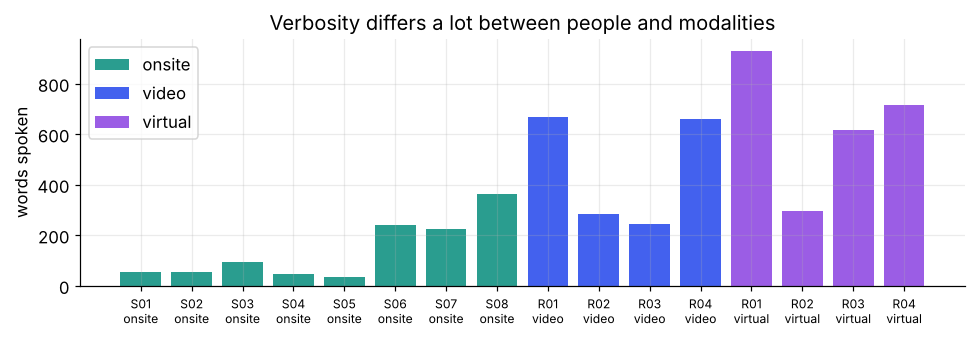

In [4]:
part = df[df.role == 'participant']
vb = part.groupby(['modality', 'session']).n_words.sum().reset_index()
fig, ax = plt.subplots(figsize=(9, 3.2))
for m in ['onsite', 'video', 'virtual']:
    d = vb[vb.modality == m]
    ax.bar(d.session + '\n' + m, d.n_words, color=COL[m], label=m)
ax.set_ylabel('words spoken'); ax.set_title('Verbosity differs a lot between people and modalities')
plt.xticks(fontsize=8); ax.legend(); plt.tight_layout(); plt.show()

## 2 · Step A — Let the data suggest keywords
Before using any dictionary, we look at which words are frequent **and** distinctive in each modality.
TF-IDF rewards words that are common in one modality but rare in others.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
STOP = list(CountVectorizer(stop_words='english').get_stop_words()) + \
       'yeah like think maybe oh ohh ok okay um uh hmm mm just really kind thing things lot know mean right sure ah eh huh yes don didn doesn look looks use'.split()
docs = part.groupby('modality').text.apply(lambda s: ' '.join(s.astype(str).str.lower())).reindex(['onsite', 'video', 'virtual'])
tf = TfidfVectorizer(stop_words=STOP, token_pattern=r'[a-z]{3,}', sublinear_tf=True)
X = tf.fit_transform(docs)
terms = np.array(tf.get_feature_names_out())
top = {m: terms[np.argsort(-X[i].toarray()[0])[:15]] for i, m in enumerate(docs.index)}
pd.DataFrame(top)

,onsite,video,virtual
0,children,fish,boxes
1,instagram,selling,frozen
2,event,street,fish
3,vegetables,temporary,price
4,stalls,vegetable,pasta
5,easily,food,color
6,dishes,little,veggie
7,suitable,people,staff
8,oriented,cook,floor
9,needed,quite,remember


## 3 · Step B — AI-assisted keyword expansion
Frequency alone misses **synonyms** ("veggie" = "vegetable") and **indirect expressions** ("the cold dessert" = *kakigori* shaved ice).
In our papers we used a large language model to *propose* synonyms and indirect expressions for each category, and then a human **reviewed every suggestion**.

Below is the prompt we use. You can paste it into any chat model (ChatGPT, Claude, Gemini) — or skip it: we load the reviewed dictionary in the next cell.

In [6]:
seed = ['signage', 'table', 'coffee', 'kakigori', 'children', 'atmosphere']
prompt = f"""You are helping analyse visitor interviews from a small morning pop-up market in Japan.
For each seed keyword below, list up to 8 synonyms, colloquial variants or indirect expressions
that a visitor might use in spoken English (including Japanese loan words).
Return CSV with columns: seed, variant.
Seed keywords: {', '.join(seed)}"""
print(prompt)

You are helping analyse visitor interviews from a small morning pop-up market in Japan.
For each seed keyword below, list up to 8 synonyms, colloquial variants or indirect expressions
that a visitor might use in spoken English (including Japanese loan words).
Return CSV with columns: seed, variant.
Seed keywords: signage, table, coffee, kakigori, children, atmosphere


In [7]:
# The human-reviewed dictionary used in this workshop
kw = pd.read_csv(f'{DATA}/keywords/keyword_dictionary.csv')
kw['variants'] = kw.variants.str.split('|')
print(kw.groupby('category').keyword.count().to_string())
kw.head(10)

category
Activities            6
Atmosphere            7
Physical Elements    10
Products              7


,category,keyword,variants
0,Physical Elements,signage,"[signage, sign, signs, signboard, billboard, b..."
1,Physical Elements,table,"[table, tables, desk]"
2,Physical Elements,seating,"[chair, chairs, seat, seats, bench, seating]"
3,Physical Elements,tent,"[tent, tents, shade, roof, umbrella]"
4,Physical Elements,display,"[display, displays, presentation, arranged, or..."
5,Physical Elements,color,"[color, colors, colour, colours, colorful, col..."
6,Physical Elements,layout,"[layout, floor, space, path, street, corner, s..."
7,Physical Elements,price,"[price, prices, price tag, cost, expensive, ch..."
8,Physical Elements,boxes,"[box, boxes, cooler, container, containers]"
9,Physical Elements,visibility,"[visible, visibility, notice, noticed, recogni..."


## 4 · Step C — Map every utterance to keywords
We scan **participant** utterances with whole-word matching. One utterance can contain several keywords.

In [8]:
import re
patterns = [(r.category, r.keyword, re.compile(r'\b(' + '|'.join(map(re.escape, r.variants)) + r')\b', re.I))
            for r in kw.itertuples()]

def find_mentions(frame):
    rows = []
    for r in frame.itertuples():
        for cat, key, pat in patterns:
            if pat.search(str(r.text)):
                rows.append(dict(modality=r.modality, session=r.session, role=r.role, turn=r.turn,
                                 category=cat, keyword=key, text=r.text))
    return pd.DataFrame(rows)

mentions = find_mentions(df)
mentions_p = mentions[mentions.role == 'participant']
print(len(mentions_p), 'participant keyword mentions')
mentions_p.sample(6, random_state=3)[['modality', 'session', 'category', 'keyword', 'text']]

468 participant keyword mentions


,modality,session,category,keyword,text
381,video,R04,Products,vegetables,vegetable look good it's bright I see people b...
207,video,R01,Physical Elements,layout,OK can we are more in their food corner now wo...
469,video,R04,Physical Elements,price,price is quite quite expensive
155,onsite,S08,Physical Elements,color,I enjoy more prominent colors such as red. I w...
827,virtual,R04,Products,vegetables,"Uh, the veggie shop, um, cold. Ice dessert? No..."
795,virtual,R03,Physical Elements,table,"Yeah, but I think the chair and the, uh, table..."


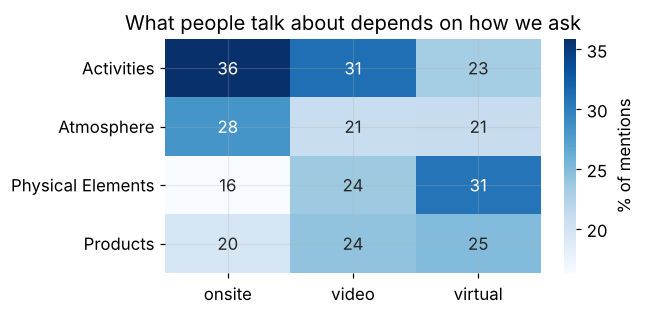

In [9]:
import seaborn as sns
tab = (mentions_p.groupby(['category', 'modality']).size().unstack().reindex(columns=['onsite', 'video', 'virtual']).fillna(0))
share = tab / tab.sum() * 100
fig, ax = plt.subplots(figsize=(6, 3))
sns.heatmap(share, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% of mentions'}, ax=ax)
ax.set_title('What people talk about depends on how we ask'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

In [10]:
# Most-mentioned keywords per modality
(mentions_p.groupby(['modality', 'keyword']).size().rename('n').reset_index()
   .sort_values(['modality', 'n'], ascending=[True, False]).groupby('modality').head(6)
   .pivot_table(index='keyword', columns='modality', values='n').fillna('').reindex(columns=['onsite', 'video', 'virtual']))

modality,onsite,video,virtual
keyword,,,
attractive,,10.0,
children,6.0,,
eating,6.0,17.0,10.0
layout,,15.0,15.0
meals,,,12.0
pleasant,8.0,,20.0
seafood & hot food,,13.0,
social media,7.0,,
vegetables,6.0,10.0,14.0


## 5 · Step D — Baseline weighted keyword score  (World 2026, §4.1)
Raw counts reward people who repeat themselves. The baseline algorithm gives each keyword mention a weight

$$\tilde w_{p,k} = m_{p,k}\; \cdot\; b(r)\; \cdot\; s_{p,k}\; \cdot\; q_{p,k}, \qquad b(r)=\max\big(0,\; w_{max}\,[1-\delta\,(r-1)]\big),\; r\le K_{max}$$

| symbol | meaning | value |
|---|---|---|
| $m$ | speaker flag — interviewer = 0, participant = 1 | 0 / 1 |
| $r$ | how many times this participant has mentioned this category so far | 1, 2, 3 … |
| $\delta$ | repetition decay | 0.25 |
| $K_{max}$ | repetitions that still count | 4 |
| $s$ | polarity of the utterance (5 levels: 0, .25, .5, .75, 1) | from sentiment |
| $q$ | transcript certainty | 1.0 |

In the paper, $s$ was assigned by hand. Here we use a quick lexicon model (VADER) so you can run everything; Notebook 2 compares it with a transformer.

In [11]:
try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
except ImportError:
    os.system('pip -q install vaderSentiment')
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

def polarity5(text):
    c = vader.polarity_scores(str(text))['compound']
    return 1.0 if c >= .5 else .75 if c >= .05 else .5 if c > -.05 else .25 if c > -.5 else 0.0

df['s'] = df.text.map(polarity5)
mentions = mentions.merge(df[['modality', 'session', 'turn', 's']], on=['modality', 'session', 'turn'], how='left')

In [12]:
W_MAX, DELTA, K_MAX = 1.0, 0.25, 4

def baseline_weights(m, delta=DELTA, kmax=K_MAX):
    m = m.sort_values(['modality', 'session', 'turn']).copy()
    m['flag'] = (m.role == 'participant').astype(int)
    m['r'] = m[m.flag == 1].groupby(['modality', 'session', 'category']).cumcount() + 1
    m['b'] = np.where(m.r <= kmax, np.maximum(0, W_MAX * (1 - delta * (m.r - 1))), 0)
    m['w'] = (m.flag * m.b.fillna(0) * m.s).round(3)
    return m

wb = baseline_weights(mentions)
# A worked example, like Table 2 in the paper
ex = wb[(wb.modality == 'video') & (wb.session == 'R02') & (wb.flag == 1)].head(8)
ex[['category', 'keyword', 'r', 'b', 's', 'w', 'text']]

,category,keyword,r,b,s,w,text
250,Physical Elements,layout,1.0,1.00,1.00,1.000,this is like in the side of city and then yeah
251,Products,vegetables,1.0,1.00,0.75,0.750,some vegetable and then like some food
252,Activities,eating,1.0,1.00,0.75,0.750,some vegetable and then like some food
255,Activities,visiting,2.0,0.75,0.25,0.188,for me my my opinion this is like it's not lik...
256,Physical Elements,tent,2.0,0.75,1.00,0.750,this is like like small tent temporary
260,Activities,buying,3.0,0.50,1.00,0.500,first I like to go around first OK around firs...
261,Activities,visiting,4.0,0.25,1.00,0.250,first I like to go around first OK around firs...
263,Products,vegetables,2.0,0.75,0.75,0.562,like Japanese foods Japanese food and then som...


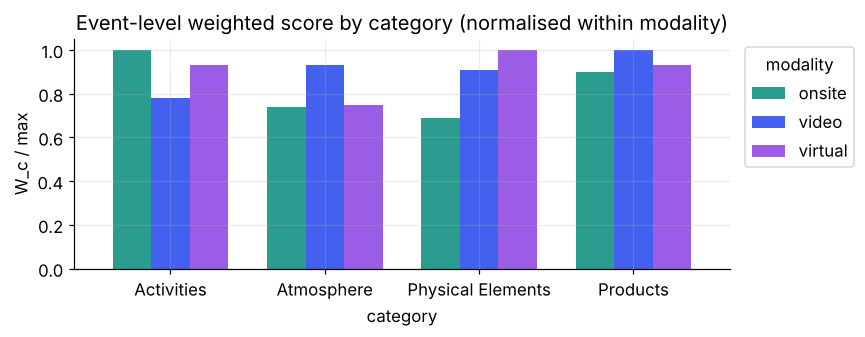

In [13]:
S = wb.groupby(['modality', 'session', 'category']).w.sum().rename('S').reset_index()
W = S.groupby(['modality', 'category']).S.mean().unstack(0).reindex(columns=['onsite', 'video', 'virtual'])
(W / W.max()).round(2).plot.bar(figsize=(8, 3.2), color=[COL[c] for c in W.columns], width=.75)
plt.title('Event-level weighted score by category (normalised within modality)'); plt.ylabel('W_c / max'); plt.legend(title='modality', bbox_to_anchor=(1.01, 1), loc='upper left'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 6 · The verbosity problem
If someone simply **talks more**, do they get a higher score? Let's check.

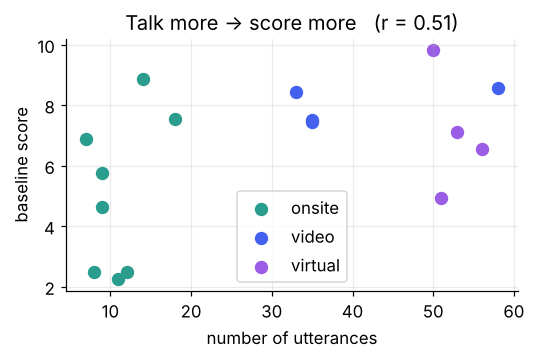

In [14]:
tot = wb.groupby(['modality', 'session']).w.sum().rename('score')
n_utt = df[df.role == 'participant'].groupby(['modality', 'session']).size().rename('utterances')
v = pd.concat([tot, n_utt], axis=1).fillna(0).reset_index()
r = v[['score', 'utterances']].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(5, 3.4))
for m in ['onsite', 'video', 'virtual']:
    d = v[v.modality == m]; ax.scatter(d.utterances, d.score, s=60, color=COL[m], label=m)
ax.set_xlabel('number of utterances'); ax.set_ylabel('baseline score'); ax.legend()
ax.set_title(f'Talk more → score more   (r = {r:.2f})'); plt.tight_layout(); plt.show()
v.to_csv(f'{RESULTS}/nb1_baseline_participant_scores.csv', index=False)
wb.to_csv(f'{RESULTS}/nb1_mentions_weighted.csv', index=False)

A strong correlation means **verbose people dominate** the event-level picture — not because their ideas are richer, but because they said more. In the paper the adaptive algorithm reduced this verbosity-driven inflation by about **45 %**. That is Notebook 2.

## ✏️ Try it yourself (3 min)
1. Change `DELTA` to `0.5` and re-run Step D. Which category drops the most?
2. Add a keyword to the dictionary (e.g. `"parking"` under *Physical Elements*) and see if anyone mentions it.
3. Which modality talks most about **Atmosphere**? Why might on-site visitors do that?

**Next →** `02_sentiment_adaptive.ipynb`